# COST 与 PageRank：在 Mac 上看懂“扩展性”和“实际速度”

这份原型回答三个问题：为什么优化单线程后加速比可能变小？PageRank 如何计算与测量？COST 论文到底得出了什么结论？

阅读顺序：先看第 1–3 节的模型，再看第 4–7 节真实实验。模型中的秒数是人为设定；实验中的秒数来自运行本 notebook 的机器。全部使用本地生成的数据，无网络或集群依赖。

**术语修正：**“单线程”描述软件执行，“单核”描述硬件资源。本文的基线是单线程实现，不给进程绑定特定 CPU 核。Mac 的调度、性能核/能效核、温度等都会影响测量。进程数也不等于实际独占的核心数。

来源：[McSherry 等，COST，2015](https://www.usenix.org/system/files/conference/hotos15/hotos15-paper-mcsherry.pdf)。这里复现的是评价方法，不复现原文的大图、硬件或系统排名。

In [1]:
import os
for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[key] = '1'
os.environ.setdefault('MPLCONFIGDIR', '/tmp/cost-pagerank-mpl')
import platform, sys, json, time
from pathlib import Path
import numpy as np
import scipy
import matplotlib.pyplot as plt
from pagerank_demo import make_graph, pagerank_python, pagerank_numpy, pagerank_sparse, parallel_trial, timed
# Optional extra protection if native libraries were loaded before this cell.
try:
    from threadpoolctl import threadpool_limits, threadpool_info
    thread_limit = threadpool_limits(limits=1)
    native_pools = threadpool_info()
except ImportError:
    native_pools = 'threadpoolctl unavailable; environment limits set before imports'
if 'show' not in globals():
    show = plt.show
print('OS:', platform.platform())
print('Python:', sys.version.split()[0], 'NumPy:', np.__version__, 'SciPy:', scipy.__version__)
print('Logical CPUs:', os.cpu_count())
print('Native pools:', native_pools)

OS: macOS-26.6.1-arm64-arm-64bit-Mach-O
Python: 3.13.5 NumPy: 2.4.1 SciPy: 1.17.1
Logical CPUs: 14
Native pools: []


## 1. “加速 50 倍”到底和谁比较？

常见的自加速比是 $S(p)=T(1)/T(p)$。它问：同一个实现增加资源之后，快了多少？

COST 关心的另一个问题是：相对于一个合理的单线程替代方案，它究竟有没有更快？对应比值是 $R(p)=T_{reference}/T(p)$。$R>1$ 才表示超过这个基线。

例如 A 从 1000 秒降到 20 秒，自加速比为 50；B 单线程只要 10 秒，那么 A 的 100 个工作单元仍然比 B 的一个线程慢。两个比值回答不同的问题。**只给自加速比，会丢掉“原来到底有多慢”这个信息。**

## 2. 为什么删除多余工作后，扩展曲线可能变差？

以下是一个专门用来说明机制的模型，不是实测：

$$T(p)=s+\frac{W+H}{p}$$

- $s$：无法并行的固定部分；
- $W$：真正需要的可并行工作，在一个工作单元上的耗时；
- $H$：实现引入、但同样可以分摊的额外工作；
- $p$：模型中的工作单元数。这里先忽略通信和内存带宽限制。

假设 A 与 B 完成同一任务，A 多了一大块可并行开销。优化只删除开销 $H$，没有改变任务或输出。

从公式看，自加速比 $S(p)=p(s+W+H)/(ps+W+H)$。当 $p>1$ 且 $s>0$，增大 $H$ 会增大自加速比！极端时，巨大的额外工作把固定串行开销掩盖了。它依然会让绝对耗时变长。

这里依赖的是“额外工作可并行”这个条件；额外开销若是串行或通信瓶颈，曲线会有不同表现。

p    A seconds    B seconds    A self-speedup    B self-speedup    A/reference gain
  1    1000.000       10.000            1.00             1.00             0.01
  2     500.500        5.500            2.00             1.82             0.02
  4     250.750        3.250            3.99             3.08             0.04
 16      63.438        1.562           15.76             6.40             0.16
 64      16.609        1.141           60.21             8.77             0.60
128       8.805        1.070          113.58             9.34             1.14


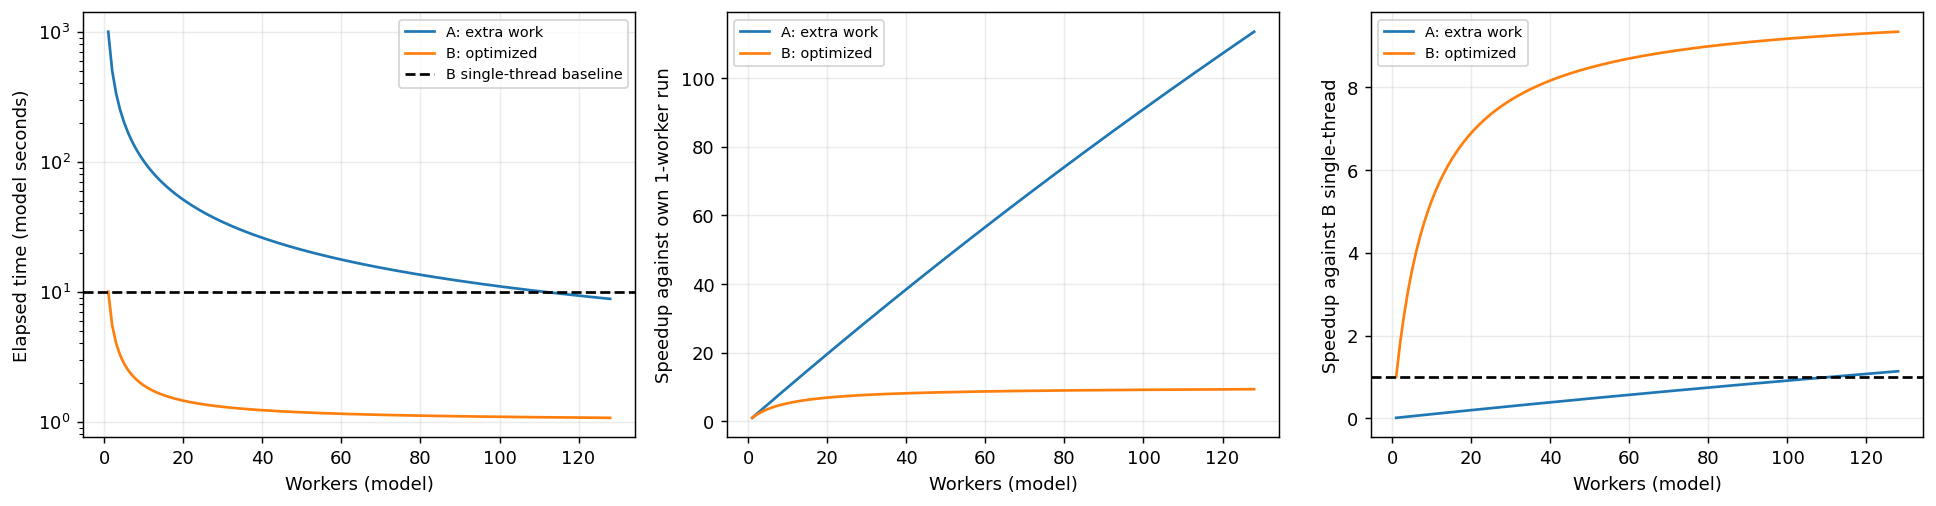

In [2]:
SERIAL = 1.0
USEFUL = 9.0
EXTRA_A = 990.0  # Try 0, 90, 990; this is artificial overhead.
EXTRA_B = 0.0
workers = np.arange(1, 129)
def model(p, extra):
    return SERIAL + (USEFUL + extra) / p
A = model(workers, EXTRA_A)
B = model(workers, EXTRA_B)
reference = model(1, EXTRA_B)
print('p    A seconds    B seconds    A self-speedup    B self-speedup    A/reference gain')
for p in (1, 2, 4, 16, 64, 128):
    a, b = model(p, EXTRA_A), model(p, EXTRA_B)
    print(f'{p:3d}  {a:10.3f}   {b:10.3f}    {A[0]/a:12.2f}     {B[0]/b:12.2f}       {reference/a:10.2f}')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for times, label in ((A, 'A: extra work'), (B, 'B: optimized')):
    ax[0].plot(workers, times, label=label)
    ax[1].plot(workers, times[0] / times, label=label)
    ax[2].plot(workers, reference / times, label=label)
ax[0].axhline(reference, color='black', linestyle='--', label='B single-thread baseline')
ax[0].set_yscale('log'); ax[0].set_ylabel('Elapsed time (model seconds)')
ax[1].set_ylabel('Speedup against own 1-worker run')
ax[2].axhline(1, color='black', linestyle='--'); ax[2].set_ylabel('Speedup against B single-thread')
for axis in ax:
    axis.set_xlabel('Workers (model)'); axis.grid(alpha=.25); axis.legend(fontsize=8)
plt.tight_layout(); show()

**读图：**左图越低越好，B 在每一种配置下都更快。中图 A 的自加速比更高，因为它最初特别慢。右图用共同基线后，B 的优势一目了然。

默认参数下，A 从 1000 秒降到约 8.8 秒，看起来加速超过 113 倍；B 从 10 秒降到约 1.07 秒，只加速约 9.3 倍。但用户实际等待的时间，B 始终更短。

优化后串行部分的**绝对时间没增加**，它在总时间中的占比增加了。因而继续增加工作单元时，剩余的加速空间减少。这就是这段论述的核心。

## 3. COST 是超过基线的门槛

在这个模型里，COST 可简化为满足 $T(p)<T_{reference}$ 的最小整数 $p$。真实论文说的是硬件配置，通常比一个整数复杂。

默认参数中，A 在 111 个工作单元时正好等于 10 秒，要到 112 个才严格超过 B 的单线程。B 在 2 个工作单元时就超过自己的单线程。

若实际只测了 1、2、4 个进程，均没有超过基线，只能写“在已测配置中未超过”。扩大配置可能交叉，也可能由于通信瓶颈始终无法交叉；这需要新的测量。

In [3]:
for label, times in [('A', A), ('B', B)]:
    faster = workers[times < reference]
    print(label, 'model COST:', int(faster[0]) if len(faster) else 'not reached in tested model range')

A model COST: 112
B model COST: 2


## 4. PageRank 先算一个四节点小图

把排名想象为随机浏览者落在各页面上的概率。一轮更新：每个页面把自己的概率平均分给所有出边，再加上随机跳转。

$$r_{new}=\alpha P r+\left((1-\alpha)+\alpha\sum_{j\in D}r_j\right)\frac{\mathbf{1}}{n}$$

这里 $P_{ij}=1/outdegree(j)$ 表示边 $j\to i$ 的转移概率；$D$ 是没有出边的节点集合。它们的概率均匀分给所有节点，保证总和为 1。我们取 $\alpha=0.85$，初值为均匀分布。

下图关系用列表表示：A → B、C；B → C；C → A；D 没有出边。A、C 会反复收到链接，D 主要靠随机跳转得到概率。

Iteration  1: [0.303125 0.196875 0.409375 0.090625] sum= 1.0
Iteration  2: [0.404727 0.185586 0.35293  0.056758] sum= 1.0
Iteration  3: [0.349551 0.22157  0.379318 0.049561] sum= 1.0
Iteration  4: [0.370452 0.196591 0.384925 0.048032] sum= 1.0
Iteration  5: [0.374893 0.205149 0.372251 0.047707] sum= 1.0
Iteration 40: [0.369324 0.204582 0.378476 0.047619] sum= 1.0
Independent stationary solution: [0.36932353 0.20458155 0.37847587 0.04761905]


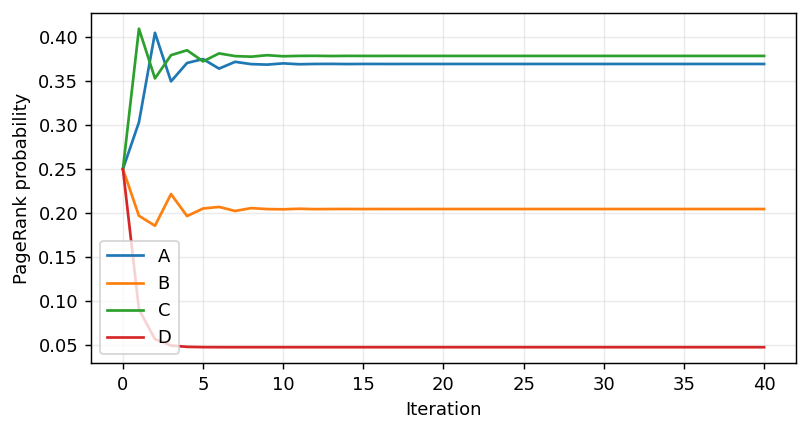

In [4]:
from scipy.sparse import csr_matrix
small_src = np.array([0, 0, 1, 2])
small_dst = np.array([1, 2, 2, 0])
small_out = np.bincount(small_src, minlength=4)
small_P = csr_matrix((1.0/small_out[small_src], (small_dst, small_src)), shape=(4, 4))
r = np.full(4, .25)
history = [r.copy()]
for step in range(40):
    r = .85*(small_P @ r + r[small_out == 0].sum()/4) + .15/4
    history.append(r.copy())
    if step < 5 or step == 39:
        print(f'Iteration {step+1:2d}:', np.round(r, 6), 'sum=', round(r.sum(), 12))
# Independent dense linear-system reference to check the equation itself.
transition = small_P.toarray()
transition[:, small_out == 0] = 1/4
exact = np.linalg.solve(np.eye(4) - .85*transition, np.full(4, .15/4))
np.testing.assert_allclose(r, exact, atol=1e-6, rtol=0)
print('Independent stationary solution:', exact)
plt.figure(figsize=(7, 3.5))
for i, name in enumerate('ABCD'):
    plt.plot(np.array(history)[:, i], label=name)
plt.xlabel('Iteration'); plt.ylabel('PageRank probability'); plt.legend(); plt.grid(alpha=.25); show()

## 5. 真实实验：同一个 PageRank，三种单线程实现

用固定随机种子生成一个有向多重图。允许重复边、自环，并保留一个无出边节点。重复边按多条链接处理；稀疏矩阵合并它们时会相加权重，因此三个实现语义一致。

1. Python 循环：逐边更新分数，容易理解，但每条边都会执行 Python 层操作。
2. NumPy：按数组取值，用 bincount 汇总目标节点收到的贡献。
3. SciPy CSR：把转移概率预先组织成稀疏矩阵，迭代时执行稀疏矩阵乘向量。

三者都执行相同的 20 轮更新。固定轮数避免不同停止条件干扰计时；20 轮是工作量定义，不保证任意图都已收敛。代码在旁边的 `pagerank_demo.py` 中。

**计时口径：**图生成和 CSR 构建单独记录；查询计时包含排名初始化。Python 实现还包含生成 Python 边列表的成本。各实现预热一次，然后计时三次取中位数。这里比较整体实现的效率，不能把差距单独归因于某一种缓存优化。

Nodes=8,000; edges=127,984; iterations=20; setup=0.001640s
Python edge loop  : median=0.097476s, samples=[0.097185 0.097476 0.098801]
NumPy bincount    : median=0.007470s, samples=[0.007955 0.006389 0.00747 ]
SciPy CSR         : median=0.001594s, samples=[0.001661 0.001592 0.001594]
Python edge loop max error: 1.3552527156068805e-19
NumPy bincount max error: 5.421010862427522e-20
SciPy CSR max error: 0.0
Python / CSR time ratio: 61.14560806038843


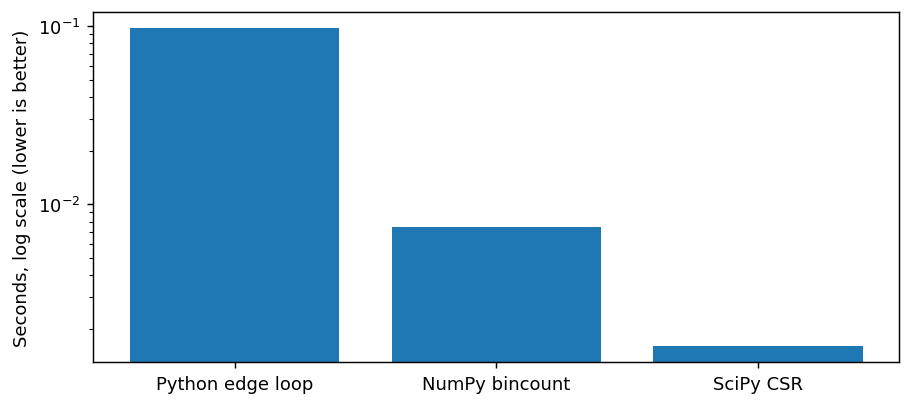

In [5]:
N = 8000
DEGREE = 16
ITERATIONS = 20
start = time.perf_counter()
src, dst, out, matrix = make_graph(N, DEGREE)
setup_s = time.perf_counter() - start
print(f'Nodes={N:,}; edges={len(src):,}; iterations={ITERATIONS}; setup={setup_s:.6f}s')
methods = {
    'Python edge loop': lambda: pagerank_python(src, dst, out, ITERATIONS),
    'NumPy bincount': lambda: pagerank_numpy(src, dst, out, ITERATIONS),
    'SciPy CSR': lambda: pagerank_sparse(matrix, out, ITERATIONS),
}
results = {}
ranks = {}
for label, fn in methods.items():
    seconds, rank, samples = timed(fn)
    results[label] = {'median_s': seconds, 'samples_s': samples}
    ranks[label] = rank
    print(f'{label:18s}: median={seconds:.6f}s, samples={np.round(samples, 6)}')
reference_rank = ranks['SciPy CSR']
for label, rank in ranks.items():
    np.testing.assert_allclose(rank, reference_rank, rtol=1e-11, atol=1e-13)
    assert np.all(rank >= 0)
    np.testing.assert_allclose(rank.sum(), 1.0, atol=1e-12)
    print(label, 'max error:', np.max(np.abs(rank-reference_rank)))
baseline_s = results['SciPy CSR']['median_s']
print('Python / CSR time ratio:', results['Python edge loop']['median_s']/baseline_s)
plt.figure(figsize=(8, 3.5))
plt.bar(results.keys(), [v['median_s'] for v in results.values()])
plt.yscale('log'); plt.ylabel('Seconds, log scale (lower is better)'); show()

## 6. 真实实验：给一个简单实现增加进程，会发生什么？

接下来把边分给 1、2、4 个子进程。每轮每个进程算一份贡献，主进程求和，再进入下一轮。所有实现的结果都与单线程 CSR 比较。

这个原型刻意保持容易读：每轮通过进程间通信发送边片段和排名，返回长度为 n 的贡献数组。这会产生序列化、复制、同步和归并成本。它代表一个朴素的并行方案，**不是优化后的并行 PageRank 性能上限**。可以进一步改成常驻图、共享内存、优化分区等方案，再重新测量。

Mac 使用 spawn 启动进程，所以工作函数放在可导入的独立模块中。启动/预热时间、预热后的查询时间、三次查询加启停的完整生命周期分别记录。查询计时仍包括每轮 IPC。主进程也参与计算，因此这里横轴叫“子进程数”，不把它当作 COST 原文的核心数。

这个小数据集可能出现增加进程反而更慢的情况。实验不预设曲线形状；出现任何结果，都要同时看自加速比和共同基线。

workers=1; startup=0.2208s; query median=0.036619s; lifecycle (3 queries)=0.3473s; PIDs=[98805]
workers=2; startup=0.2170s; query median=0.031174s; lifecycle (3 queries)=0.3299s; PIDs=[98806, 98807]
workers=4; startup=0.2355s; query median=0.033742s; lifecycle (3 queries)=0.3561s; PIDs=[98808, 98809, 98810, 98811]

workers | self speedup | speedup vs single-thread CSR | relative elapsed time
      1 |        1.000 |                        0.044 |                 22.97x
      2 |        1.175 |                        0.051 |                 19.56x
      4 |        1.085 |                        0.047 |                 21.17x
First measured process count beating CSR: None in {1, 2, 4}; no claim about larger configurations.


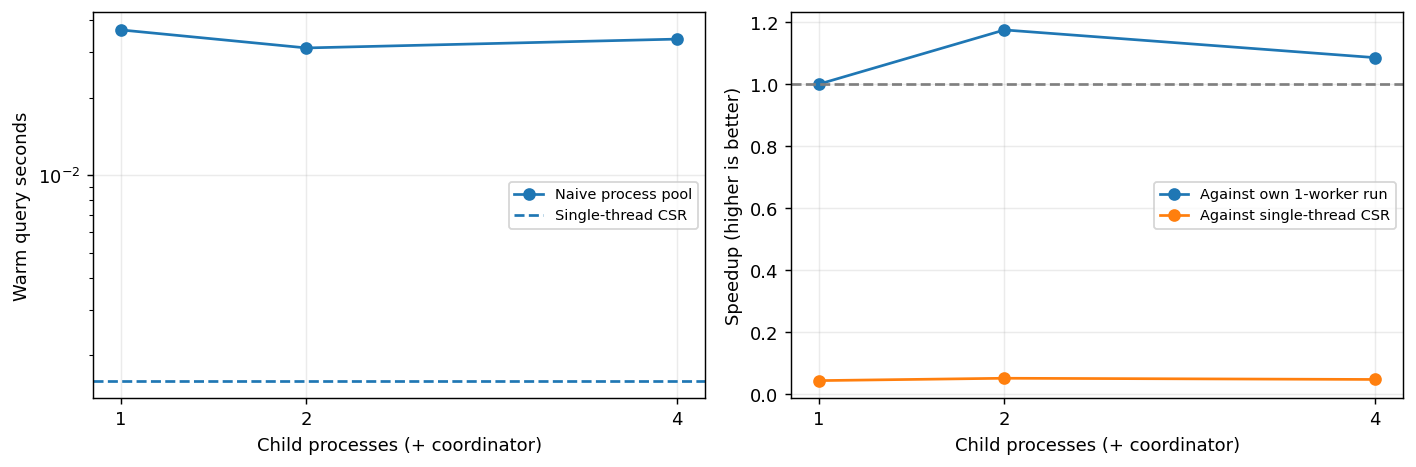

In [6]:
parallel_results = []
for p in (1, 2, 4):
    stats, rank = parallel_trial(src, dst, out, p, ITERATIONS)
    np.testing.assert_allclose(rank, reference_rank, rtol=1e-11, atol=1e-13)
    parallel_results.append(stats)
    print(f"workers={p}; startup={stats['startup_s']:.4f}s; query median={stats['query_s']:.6f}s; "
          f"lifecycle (3 queries)={stats['lifecycle_s']:.4f}s; PIDs={stats['observed_pids']}")
one_worker_s = parallel_results[0]['query_s']
print('\nworkers | self speedup | speedup vs single-thread CSR | relative elapsed time')
for stats in parallel_results:
    t = stats['query_s']
    print(f"{stats['workers']:7d} | {one_worker_s/t:12.3f} | {baseline_s/t:28.3f} | {t/baseline_s:21.2f}x")
ps = [x['workers'] for x in parallel_results]
ts = [x['query_s'] for x in parallel_results]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(ps, ts, 'o-', label='Naive process pool')
axes[0].axhline(baseline_s, linestyle='--', label='Single-thread CSR')
axes[0].set_ylabel('Warm query seconds'); axes[0].set_yscale('log')
axes[1].plot(ps, one_worker_s/np.array(ts), 'o-', label='Against own 1-worker run')
axes[1].plot(ps, baseline_s/np.array(ts), 'o-', label='Against single-thread CSR')
axes[1].axhline(1, color='gray', linestyle='--'); axes[1].set_ylabel('Speedup (higher is better)')
for axis in axes:
    axis.set_xlabel('Child processes (+ coordinator)'); axis.set_xticks(ps); axis.legend(fontsize=8); axis.grid(alpha=.25)
plt.tight_layout(); show()
beats = [s['workers'] for s in parallel_results if s['query_s'] < baseline_s]
print('First measured process count beating CSR:', min(beats) if beats else 'None in {1, 2, 4}; no claim about larger configurations.')
report = {'platform': platform.platform(), 'python': sys.version.split()[0],
          'numpy': np.__version__, 'scipy': scipy.__version__, 'nodes': N, 'edges': len(src),
          'iterations': ITERATIONS, 'setup_s': setup_s, 'single_thread': results,
          'parallel': parallel_results, 'baseline': 'SciPy CSR'}
Path('results.json').write_text(json.dumps(report, indent=2))

## 7. 这些测量能说明什么？

先自己读上面的输出，再用这四句话组织结论：

1. 三种串行实现计算的是同一个数学结果，耗时却不同。合理基线应考虑有效的数据结构和执行方式。
2. 并行实现相对于自身一个进程快了多少，和相对于 CSR 快了多少，是两个不同的数字。
3. 如果 1、2、4 个进程都没超过 CSR，我们只报告这个实验范围内没有回本。这个实验没有测试多机、真实大图或高度优化的并行实现。
4. 数学模型展示“更慢的实现也能有更漂亮的扩展性”；真实实验展示怎样用共同基线评价一个方案。真实实验不必出现与模型完全相同的形状。

本地结果还受到系统负载、CPU 核类型、频率和缓存的影响。若两种实现耗时接近，应增加运行次数、观察分布，再作判断；不要把一次几毫秒的优势当作稳定结论。

**可以做的下一步：**把 N 改为 40000，重跑第 5、6 节，观察计算/通信比例变化；或者把并行实现的图常驻在 worker 中，减少重复发送，再观察 COST 门槛如何变化。每次都保留同样的正确性检查。

## 8. 回到论文：结论到底是什么？

**COST 的主张是：评价可扩展系统时，要用一个合理的简单实现检查它的绝对性能。** 扩展曲线回答“加资源是否变快”；单线程基线回答“这个复杂系统提供了多少实际收益”。两个问题都值得回答。

原文进一步展示了两类改进方向：同一个算法可以改善数据布局；同一个任务也可以改用工作量更少的算法。比如连通分量任务中，标签传播与并查集是在解决同一问题，但工作量很不同。本 notebook 的 PageRank 保持算法相同，侧重实现效率和系统开销，没有模拟这项换算法实验。

因此它对工程选择的建议是：先把一个合理的简单方案量清楚，再判断额外资源带来的收益。大容量、吞吐、可用性、共享访问等需求仍可能使分布式系统成为合适选择；COST 衡量的是固定任务上的性能门槛，而非所有功能的总价值。

**与 DuckDB 那篇的关系：**2019 年 DuckDB 论文提出把分析数据库嵌入应用，围绕批量执行、数据交换和宿主资源使用做设计。它主要是架构与演示论文。两篇放在一起，可以理解为：COST 提醒你识别多余工作，DuckDB 提供一种减少分析场景中系统开销的架构方向。这是阅读上的联系，不是本 demo 已经验证 DuckDB 的性能。

[DuckDB 原文](https://ir.cwi.nl/pub/28800/28800.pdf)

### 用自己的话回答这三个问题

- A 单线程 1000 秒，100 个工作单元 20 秒；B 单线程 10 秒。A 加速了多少？相对 B 又怎样？
- 删除可并行的额外工作后，哪些时间减少了？为什么自加速比可能变小？
- 一个并行方案用了 4 个子进程仍比 CSR 慢，下一步应先检查哪些开销？

参考答案：50 倍，但仍比 B 慢 2 倍；绝对耗时减少，而固定串行部分的占比增加；检查序列化、数据复制、同步、分区、内存带宽与总工作量，并以相同结果和计时口径重新测量。